# POTT Analysis for all noise levels

Some figures shown in this notebook are not included in the manuscript. The one we decided to include in the paper will be explicitly labeled.

In [1]:
using DelimitedFiles
using PeriodicOrbitTTV

using JLD2

using PyPlot
using LaTeXStrings
using Distributions, LinearAlgebra, StatsBase

In [2]:
rcParams = PyPlot.PyDict(PyPlot.matplotlib."rcParams")
rcParams["text.usetex"] = true

true

We will only restrict the analysis to the converged optimizations and reject the unconverged ones.

In [3]:
# Load all util functions and objects
obj = jldopen("../frequentist/run_freq_multi_noise_01s_07_03s_07.jld2")

clean_params = vec(readdlm("../frequentist/sample_orbit_v1.in"))
clean_params[4:8] .= rem2pi.(clean_params[4:8], RoundNearest)

function get_valid_indices(optres_arr)
    idx_arr = []
    for i in eachindex(optres_arr)
        if isassigned(optres_arr[i], length(optres_arr[i]))
            push!(idx_arr, i)
        end
    end

    return idx_arr
end

function find_converged_pott_idx(optres_arr, po_weight; valid_idx=valid_idx)
    idx_arr = []
    for i in eachindex(optres_arr)
        if i in valid_idx
            chi2 = sum(abs2, optres_arr[i][end].resid[1:26])
            chi2_tt = sum(abs2, optres_arr[i][end].resid[27:end])
        
            if (chi2 ./ po_weight < 1e-12) & (chi2_tt <= 1e2)
                push!(idx_arr, i)
            end
        end
    end

    return idx_arr
end

function find_converged_bad_tt_idx(optres_arr, po_weight; valid_idx=valid_idx)
    idx_arr = []
    for i in eachindex(optres_arr)
        if i in valid_idx
            chi2 = sum(abs2, optres_arr[i][end].resid[1:26])
            chi2_tt = sum(abs2, optres_arr[i][end].resid[27:end])
        
            if (chi2 ./ po_weight < 1e-12) & (chi2_tt > 1e3)
                push!(idx_arr, i)
            end
        end
    end

    return idx_arr
end

column_display = [L"e_{1}", L"e_{2}", L"e_{3}", 
    L"M_1", L"M_2", L"M_3",
    L"\Delta \omega_{21}", L"\Delta \omega_{32}",
    L"\delta P_{23}",
    L"P_1",
    L"m_1", L"m_2", L"m_3",
    L"\kappa", L"\omega_1", L"T_{sys}"];

valid_idx = get_valid_indices(obj["optres"])
converged_idx = find_converged_pott_idx(obj["optres"], obj["weights"][end]);

In [4]:
@show length(obj["optres"])
@show length(valid_idx) / length(obj["optres"])
@show length(converged_idx) / length(obj["optres"])
@show length(converged_idx) / length(valid_idx)

length(obj["optres"]) = 1000
length(valid_idx) / length(obj["optres"]) = 0.974
length(converged_idx) / length(obj["optres"]) = 0.389
length(converged_idx) / length(valid_idx) = 0.3993839835728953


0.3993839835728953

# Produce Figure 3c (to be removed)

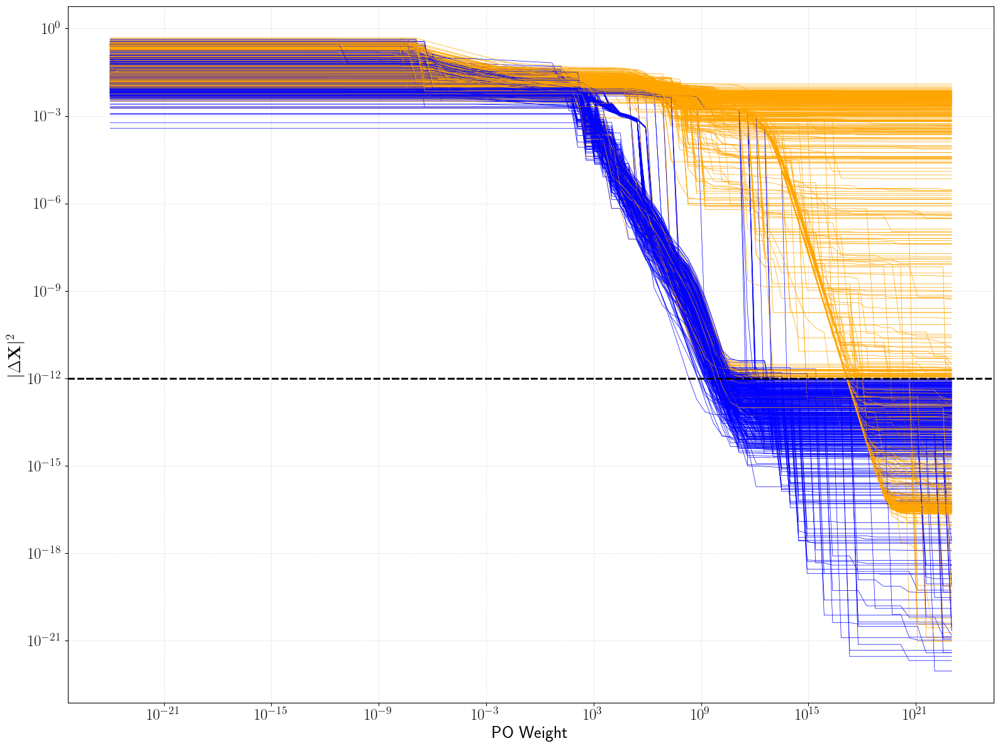

In [5]:
fig, ax = subplots(figsize=(16,12), tight_layout=true)

for j in valid_idx
    chi2 = [sum(abs2, obj["optres"][j][i].resid[1:10]) for i in 1:100]
    po_weights = obj["weights"][1:100]

    if !(j in converged_idx)
        ax.plot(po_weights, chi2 ./ po_weights, color="orange", linewidth=0.5)
    else
        ax.plot(po_weights, chi2 ./ po_weights, color="blue", linewidth=0.5)
    end

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlabel("PO Weight", fontsize=20)
    ax.set_ylabel(L"|\Delta \mathbf{X}|^2", fontsize=20)

    ax.tick_params("both", labelsize=18)

    ax.axhline(1e-12, linestyle="--", linewidth=2, color="black")

    ax.grid(linestyle="--", alpha=0.3)
end

# fig.savefig("figures/main_po_chi2_diff_rescaled.pdf")

From this onward, the variables with suffix `_tt` correspond to the transit timing only solutions.

In [6]:
# Load all converged runs
params_all = reduce(hcat, [[(obj["optres"][i][100].param .* obj["scaler"][i])[param_idx] for i in converged_idx] for param_idx in 1:16]);
params_all_tt = reduce(hcat, [[(obj["optres"][i][1].param .* obj["scaler"][i])[param_idx] for i in converged_idx] for param_idx in 1:16]);

# Parameters of interest are eccentricities, masses, and the innermost period
pois = [1, 2, 3, 10, 11, 12, 13];

# Analysis

## Compare whether the distribution of the optimized parameters follow normal distributions.

In [7]:
function plot_hist_gaussian(ax, params, idx, quantiles=[0.01, 0.99])
    sd = std(params[:,idx])
    gg = Normal(mean(params[:,idx]), sd)
    xx = LinRange(mean(params[:,idx]) .- 4*sd, mean(params[:,idx]) .+ 4*sd, 101)
    
    data = params[:,idx]
    lo, hi = quantile(data, quantiles)
    filtered_data = data[lo .≤ data .≤ hi]   # logical indexing variant
    
    hists = hist(filtered_data, bins=30)
    bin_size = abs.(hists[2][1:end-1] - hists[2][2:end])
    area = sum(hists[1] .* bin_size)
    
    xlim(mean(params[:,idx]) - 6*sd, mean(params[:,idx]) + 6*sd)
    plot(xx, pdf(gg, xx) .* area)
end

function plot_cum_gaussian(ax, params, idx, cparams; kwargs...)
    params = params[:,idx]

    ranges = get(kwargs, :lims, nothing)
    if ranges === nothing
        xx = LinRange(-4*std(params), 4*std(params), 101)
    else
        xx = LinRange(-ranges, ranges, 201)        
    end
    # ax.plot(xx, ecdf(params .- mean(params))(xx), label="ECDF", linestyle="-.")
    ax.plot(xx, ecdf(params .- cparams[idx])(xx), label="ECDF", linestyle="-.")
    ax.plot(xx, cdf.(Normal(mean(params) - cparams[idx], std(params)), xx), label="CDF")
end

plot_cum_gaussian (generic function with 1 method)

The left panel is POTT solution, whereas the right panel is the TT-only solution.

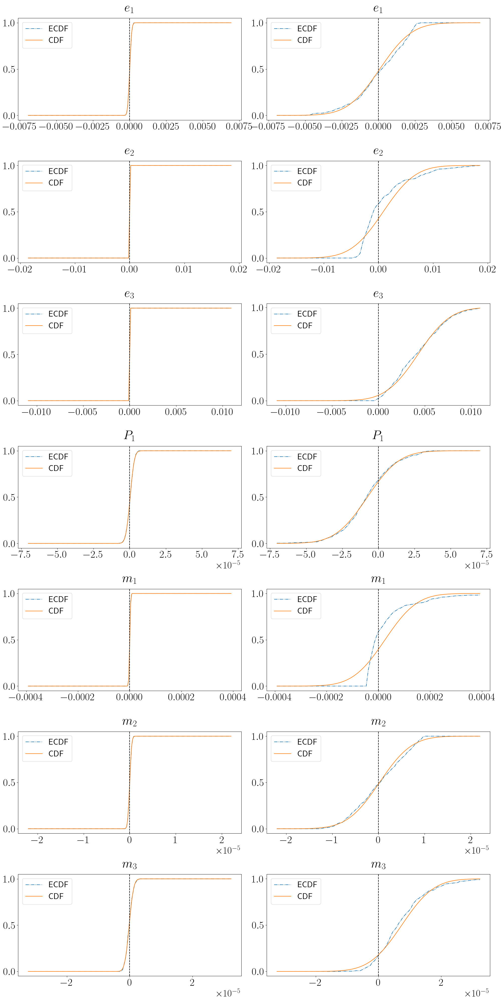

In [8]:
fig, ax = subplots(7, 2, figsize=(20,40), tight_layout=true)

for (idx, param_idx) in enumerate(pois)
    plot_cum_gaussian(ax[idx, 1], params_all, param_idx, clean_params; lims=4*std(params_all_tt[:,param_idx]))
    plot_cum_gaussian(ax[idx, 2], params_all_tt, param_idx, clean_params)
    
    ax[idx, 1].get_xaxis().get_offset_text().set_fontsize(28)
    ax[idx, 2].get_xaxis().get_offset_text().set_fontsize(28)

    ax[idx, 1].set_title(column_display[param_idx], fontsize=36, pad=20)
    # ax[idx, 1].set_ylabel(L"\mathrm{Cumulative\ Probability}", fontsize=36)

    ax[idx, 2].set_title(column_display[param_idx], fontsize=36, pad=20)

    ax[idx, 1].tick_params(labelsize=30)
    ax[idx, 2].tick_params(labelsize=30)

    ax[idx, 1].axvline(0., linestyle="--", c="k")
    ax[idx, 2].axvline(0., linestyle="--", c="k")

    ax[idx, 1].set_xlim(ax[idx, 2].get_xlim()...)

    ax[idx, 1].legend(fontsize=24)
    ax[idx, 2].legend(fontsize=24)

end

# fig.savefig("figures/reduced_cdf_params_03s.pdf")

## Create corner plots

In [9]:
function plot_joint(ax, params, i, j; kwargs...)
    x_param = params[:,i]
    y_param = params[:,j]

    ax.scatter(x_param, y_param, alpha=get(kwargs, :alpha, 1.0), color=get(kwargs, :color, "tab:blue"))

    limit_x = (quantile(x_param, 0.025) - std(x_param), quantile(x_param, 0.975) + std(x_param))
    limit_y = (quantile(y_param, 0.025) - std(y_param), quantile(y_param, 0.975) + std(y_param))
    
    ax.set_xlim(limit_x...)
    ax.set_ylim(limit_y...)

    return limit_x, limit_y
end

function plot_marginal(ax, params, i; kwargs...)
    x_param = params[:,i]
    # x_param = x_param[(x_param .>= quantile(x_param, 0.025)) .& (x_param .<= quantile(x_param, 0.975))]

    # Renormalize the histogram    
    heights, boundaries = ax.hist(
        x_param,
        bins=get(kwargs, :bins, 20),
        density=true,
        alpha=get(kwargs, :alpha, 1.0),
        color=get(kwargs, :color, "tab:blue")
    )
    
    ax.set_xlim(quantile(x_param, 0.025) - std(x_param), quantile(x_param, 0.975) + std(x_param))

    return boundaries, (quantile(x_param, 0.025) - std(x_param), quantile(x_param, 0.975) + std(x_param))
end

# Joint
function plot_truth(ax, cparams, i, j)
    ax.axvline(cparams[i])
    ax.axhline(cparams[j])
end

# Marginal
function plot_truth(ax, cparams, i)
    ax.axvline(cparams[i], zorder=1, linestyle="--", c="k")
end

function plot_overlay_gaussian(ax, params, idx, cparams; kwargs...)
    params = params[:,idx]

    ranges = get(kwargs, :lims, nothing)
    if ranges === nothing
        xx = LinRange(mean(params)-4*std(params), mean(params)+4*std(params), 101)
    else
        xx = LinRange(-ranges, ranges, 201)        
    end

    ax.plot(xx, pdf.(Normal(mean(params), std(params)), xx), c="k", linewidth=4, linestyle="-.")
end

plot_overlay_gaussian (generic function with 1 method)

### Corner plots for POTT and TT-only solutions for certain parameters of interest

Reproduce Figure 6

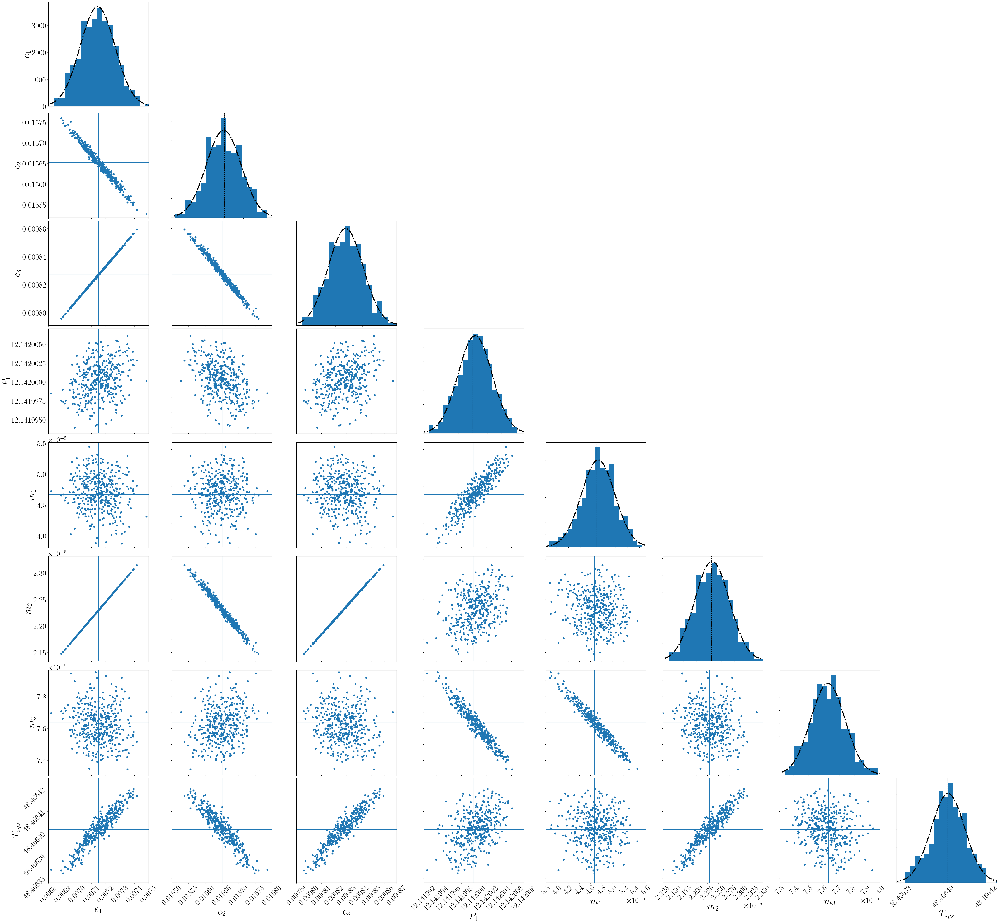

In [10]:
fig, ax = subplots(8, 8, figsize=(52,48), constrained_layout=true)

# Parameters of interests are eccentricites, masses, innermost period, and system period
pindex = [1, 2, 3, 10, 11, 12, 13, 16]
params_interest = params_all[:,pindex]

for i in 1:8  # Row
    for j in 1:8  # Column
        ax[i,j].get_xaxis().get_offset_text().set_fontsize(28)
        ax[i,j].get_yaxis().get_offset_text().set_fontsize(28)

        ax[i,j].ticklabel_format(useOffset=false)

        ax[i,j].tick_params(axis="both", labelbottom=false, labelleft=false)
        if i == j  # Plot marginal posteriors
            plot_marginal(ax[i,j], params_interest, i)
            plot_truth(ax[i,j], clean_params, pindex[i])
            plot_overlay_gaussian(ax[i,j], params_all, pindex[i], clean_params)
            
        elseif j < i  # Plot joint posteriors
            plot_joint(ax[i,j], params_interest, j, i)
            plot_truth(ax[i,j], clean_params, pindex[j], pindex[i])
        else
            ax[i,j].axis("off")
        end
    end
end

# Save x ticks and labels
for j in 1:8
    for i in j:8
        if i == j
            global shared_x_lims = ax[i,i].get_xlim()
            global shared_x_ticks = ax[i,i].get_xticks()
        else
    
            ax[i,j].set_xlim(shared_x_lims)
            ax[i,j].set_xticks(shared_x_ticks)
        end
    end
end

# Save y ticks and labels
for i in 1:8
    for j in i:1
        if i == j
            global shared_y_lims = ax[i,i].get_xlim()
            global shared_y_ticks = ax[i,i].get_xticks()
        else
            ax[i,j].set_ylim(shared_y_lims)
            ax[i,j].set_yticks(shared_y_ticks)
        end
    end
end

# Hide tick labels
for i in 1:8
    ax[i,1].tick_params(axis="both", labelbottom=false, labelleft=true)
    ax[end,i].set_xlabel(column_display[pindex[i]], fontsize=36)
    
    ax[end,i].tick_params(axis="both", labelbottom=true, labelleft=false, labelrotation=45)
    ax[i,1].set_ylabel(column_display[pindex[i]], fontsize=36)

    ax[i,1].tick_params("both", labelsize=30)
    ax[end,i].tick_params("both", labelsize=30)
end

ax[end,1].tick_params(axis="both", labelbottom=true, labelleft=true, labelrotation=45)

# fig.savefig("figures/reduced_corner_pott_01.pdf")

Produce Figure 5

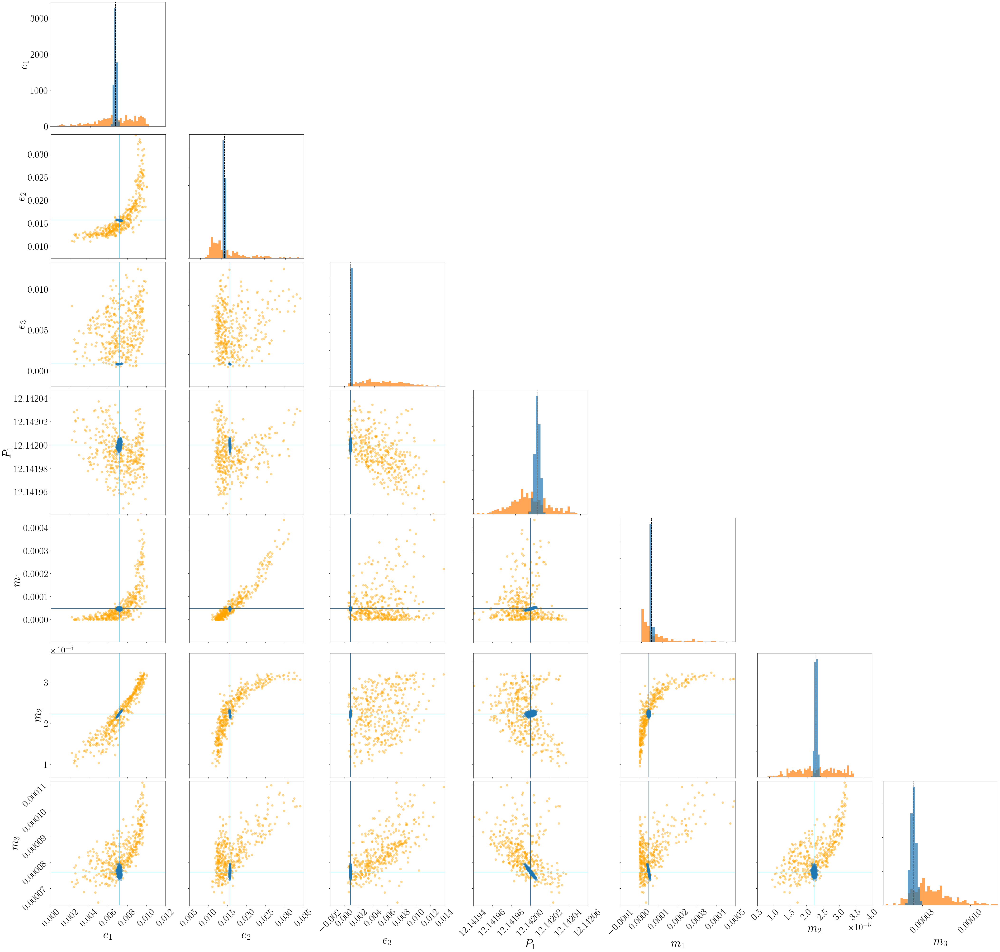

In [11]:
fig, ax = PyPlot.subplots(7, 7, figsize=(42,40), constrained_layout=true)

# Parameters of interests are eccentricites, masses, innermost period.
# System period is irrelevant in this context.
pindex = [1, 2, 3, 10, 11, 12, 13]
params_interest_tt = params_all_tt[:,pindex]
params_interest = params_all[:,pindex]

# Confine the limit of the plot
lower_quantile = 0.001
upper_quantile = 0.999

for i in 1:7  # Row
    for j in 1:7  # Column
        ax[i,j].get_xaxis().get_offset_text().set_fontsize(28)
        ax[i,j].get_yaxis().get_offset_text().set_fontsize(28)

        ax[i,j].ticklabel_format(useOffset=false)

        ax[i,j].tick_params(axis="both", labelbottom=false, labelleft=false)
        if i == j  # Plot marginal posteriors
            boundaries, limits = plot_marginal(ax[i,j], params_interest_tt, i; alpha=0.7, bins=50, color="tab:orange")
            plot_marginal(ax[i,j], params_interest, i; alpha=0.7, bins=boundaries, color="tab:blue")
            plot_truth(ax[i,j], clean_params, pindex[i])
            ax[i,j].set_xlim(limits...)
            # ax[i,j].set_xlabel(column_display[pindex[i]], fontsize=36)
            # ax[i,j].tick_params("both", labelsize=30)
            
        elseif j < i  # Plot joint posteriors
            plot_truth(ax[i,j], clean_params, pindex[j], pindex[i])
            limit_x, limit_y = plot_joint(ax[i,j], params_interest_tt, j, i, alpha=0.4, color="orange")
            plot_joint(ax[i,j], params_interest, j, i, alpha=0.4, color="tab:blue")
            ax[i,j].set_xlim(limit_x...)
            ax[i,j].set_ylim(limit_y...)
            # ax[i,j].set_xlabel(column_display[pindex[i]], fontsize=36)
            # ax[i,j].set_ylabel(column_display[pindex[j]], fontsize=36)
            # ax[i,j].tick_params("both", labelsize=30)
        else
            ax[i,j].axis("off")
        end
    end
end

# Save x ticks and labels
for j in 1:7
    for i in j:7
        if i == j
            global shared_x_lims = ax[i,i].get_xlim()
            global shared_x_ticks = ax[i,i].get_xticks()
        else
    
            ax[i,j].set_xlim(shared_x_lims)
            ax[i,j].set_xticks(shared_x_ticks)
        end
    end
end

# Save y ticks and labels
for i in 1:7
    for j in i:1
        if i == j
            global shared_y_lims = ax[i,i].get_xlim()
            global shared_y_ticks = ax[i,i].get_xticks()
        else
            ax[i,j].set_ylim(shared_y_lims)
            ax[i,j].set_yticks(shared_y_ticks)
        end
    end
end

# Hide tick labels
for i in 1:7
    ax[i,1].tick_params(axis="both", labelbottom=false, labelleft=true)
    ax[end,i].set_xlabel(column_display[pindex[i]], fontsize=36)
    
    ax[end,i].tick_params(axis="both", labelbottom=true, labelleft=false, labelrotation=45)
    ax[i,1].set_ylabel(column_display[pindex[i]], fontsize=36)

    ax[i,1].tick_params("both", labelsize=30)
    ax[end,i].tick_params("both", labelsize=30)
end

ax[end,1].tick_params(axis="both", labelbottom=true, labelleft=true, labelrotation=45)

fig.savefig("figures/reduced_corner_both_02.pdf")

### Now do the same for ALL parameters

The TT-only solution has one fewer parameter (i.e., no system period) because it is meaningless in this context.

In [12]:
fig, ax = PyPlot.subplots(16, 16, figsize=(100,80), constrained_layout=true)

pindex = 1:16
params_interest_tt = params_all_tt[:,pindex]
params_interest = params_all[:,pindex]

lower_quantile = 0.001
upper_quantile = 0.999

for i in 1:16  # Row
    for j in 1:16  # Column
        ax[i,j].get_xaxis().get_offset_text().set_fontsize(28)
        ax[i,j].get_yaxis().get_offset_text().set_fontsize(28)

        ax[i,j].ticklabel_format(useOffset=false)

        ax[i,j].tick_params(axis="both", labelbottom=false, labelleft=false)
        if i == j  # Plot marginal posteriors
            plot_marginal(ax[i,j], params_interest, i)
            plot_truth(ax[i,j], clean_params, pindex[i])
            plot_overlay_gaussian(ax[i,j], params_all, pindex[i], clean_params)
            
        elseif j < i  # Plot joint posteriors
            plot_joint(ax[i,j], params_interest, j, i)
            plot_truth(ax[i,j], clean_params, pindex[j], pindex[i])
        else
            ax[i,j].axis("off")
        end
    end
end

# Save x ticks and labels
for j in 1:16
    for i in j:16
        if i == j
            global shared_x_lims = ax[i,i].get_xlim()
            global shared_x_ticks = ax[i,i].get_xticks()
        else
    
            ax[i,j].set_xlim(shared_x_lims)
            ax[i,j].set_xticks(shared_x_ticks)
        end
    end
end

# Save y ticks and labels
for i in 1:16
    for j in i:1
        if i == j
            global shared_y_lims = ax[i,i].get_xlim()
            global shared_y_ticks = ax[i,i].get_xticks()
        else
            ax[i,j].set_ylim(shared_y_lims)
            ax[i,j].set_yticks(shared_y_ticks)
        end
    end
end

# Hide tick labels
for i in 1:16
    ax[i,1].tick_params(axis="both", labelbottom=false, labelleft=true)
    ax[end,i].set_xlabel(column_display[pindex[i]], fontsize=36)
    
    ax[end,i].tick_params(axis="both", labelbottom=true, labelleft=false, labelrotation=45)
    ax[i,1].set_ylabel(column_display[pindex[i]], fontsize=36)

    ax[i,1].tick_params("both", labelsize=30)
    ax[end,i].tick_params("both", labelsize=30)
end

ax[end,1].tick_params(axis="both", labelbottom=true, labelleft=true, labelrotation=45)

# fig.savefig("figures/full_corner_pott_01.pdf")

Produce Figure 8

In [13]:
fig, ax = PyPlot.subplots(15, 15, figsize=(74,70), constrained_layout=true)

# Exclude the last parameter (which is T_sys)
pindex = 1:15
params_interest_tt = params_all_tt[:,pindex]
params_interest = params_all[:,pindex]

lower_quantile = 0.001
upper_quantile = 0.999

for i in 1:15  # Row
    for j in 1:15  # Column
        ax[i,j].get_xaxis().get_offset_text().set_fontsize(28)
        ax[i,j].get_yaxis().get_offset_text().set_fontsize(28)

        ax[i,j].ticklabel_format(useOffset=false)

        ax[i,j].tick_params(axis="both", labelbottom=false, labelleft=false)
        if i == j  # Plot marginal posteriors
            boundaries, limits = plot_marginal(ax[i,j], params_interest_tt, i; alpha=0.7, bins=50, color="tab:orange")
            plot_marginal(ax[i,j], params_interest, i; alpha=0.7, bins=boundaries, color="tab:blue")
            plot_truth(ax[i,j], clean_params, pindex[i])
            ax[i,j].set_xlim(limits...)
            # ax[i,j].set_xlabel(column_display[pindex[i]], fontsize=36)
            # ax[i,j].tick_params("both", labelsize=30)
            
        elseif j < i  # Plot joint posteriors
            plot_truth(ax[i,j], clean_params, pindex[j], pindex[i])
            limit_x, limit_y = plot_joint(ax[i,j], params_interest_tt, j, i, alpha=0.4, color="orange")
            plot_joint(ax[i,j], params_interest, j, i, alpha=0.4, color="tab:blue")
            ax[i,j].set_xlim(limit_x...)
            ax[i,j].set_ylim(limit_y...)
            # ax[i,j].set_xlabel(column_display[pindex[i]], fontsize=36)
            # ax[i,j].set_ylabel(column_display[pindex[j]], fontsize=36)
            # ax[i,j].tick_params("both", labelsize=30)
        else
            ax[i,j].axis("off")
        end
    end
end

# Save x ticks and labels
for j in 1:15
    for i in j:15
        if i == j
            global shared_x_lims = ax[i,i].get_xlim()
            global shared_x_ticks = ax[i,i].get_xticks()
        else
    
            ax[i,j].set_xlim(shared_x_lims)
            ax[i,j].set_xticks(shared_x_ticks)
        end
    end
end

# Save y ticks and labels
for i in 1:15
    for j in i:1
        if i == j
            global shared_y_lims = ax[i,i].get_xlim()
            global shared_y_ticks = ax[i,i].get_xticks()
        else
            ax[i,j].set_ylim(shared_y_lims)
            ax[i,j].set_yticks(shared_y_ticks)
        end
    end
end

# Hide tick labels
for i in 1:15
    ax[i,1].tick_params(axis="both", labelbottom=false, labelleft=true)
    ax[end,i].set_xlabel(column_display[pindex[i]], fontsize=36)
    
    ax[end,i].tick_params(axis="both", labelbottom=true, labelleft=false, labelrotation=45)
    ax[i,1].set_ylabel(column_display[pindex[i]], fontsize=36)

    ax[i,1].tick_params("both", labelsize=30)
    ax[end,i].tick_params("both", labelsize=30)
end

ax[end,1].tick_params(axis="both", labelbottom=true, labelleft=true, labelrotation=45)

# fig.savefig("figures/full_corner_both_02.pdf")

# Chi-square Visualization

Inspect whether the chi-squares of the converged run follow the chi-square distribution with expected degrees of freedoms.

In [14]:
chi2 = [[sum(abs2, obj["optres"][j][i].resid[27:end]) for i in 1:100] for j in converged_idx];

chi2_low = reduce(hcat, chi2)[1,:];
chi2_high = reduce(hcat, chi2)[end,:];

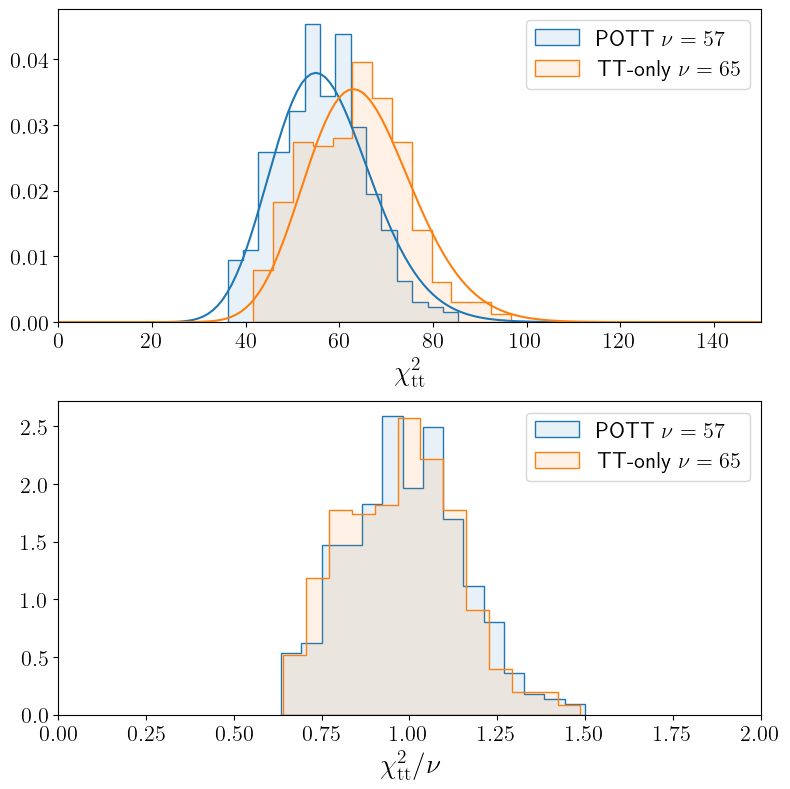

PyObject <matplotlib.legend.Legend object at 0x17e341f90>

In [15]:
fig, ax = subplots(2, 1, figsize=(8,8), tight_layout=true)

dof_tt = 72 - 15
dof_pott = 72 - 7

label_pott = "TT-only " * L"\nu = %$(dof_pott)"
label_tt = "POTT " * L"\nu = %$(dof_tt)"

xx = LinRange(0, 300, 301)

blue_color_solid = matplotlib.colors.to_rgba("tab:blue")
blue_color_trans = matplotlib.colors.to_rgba("tab:blue", alpha=0.1)

orange_color_solid = matplotlib.colors.to_rgba("tab:orange")
orange_color_trans = matplotlib.colors.to_rgba("tab:orange", alpha=0.1)

_, bins = ax[1].hist(chi2_low, bins="fd", density=true, color=blue_color_trans, edgecolor=blue_color_solid, histtype="stepfilled", label=label_tt)
ax[1].plot(xx, pdf(Chisq(dof_tt), xx), color=blue_color_solid)

ax[1].hist(chi2_high, bins="fd", density=true, color=orange_color_trans, edgecolor=orange_color_solid, histtype="stepfilled", label=label_pott)
ax[1].plot(xx, pdf(Chisq(dof_pott), xx), color=orange_color_solid)

ax[1].set_xlim(0,150)

ax[1].set_xlabel(L"\chi^2_{\mathrm{tt}}", fontsize=20)

ax[1].tick_params(labelsize=16)

ax[1].legend(fontsize=16)

# ====

blue_color_solid = matplotlib.colors.to_rgba("tab:blue")
blue_color_trans = matplotlib.colors.to_rgba("tab:blue", alpha=0.1)

orange_color_solid = matplotlib.colors.to_rgba("tab:orange")
orange_color_trans = matplotlib.colors.to_rgba("tab:orange", alpha=0.1)

_, bins = ax[2].hist(chi2_low ./ (dof_tt), bins="fd", density=true, color=blue_color_trans, edgecolor=blue_color_solid, histtype="stepfilled", label=label_tt)

ax[2].hist(chi2_high ./ (dof_pott), bins="fd", density=true, color=orange_color_trans, edgecolor=orange_color_solid, histtype="stepfilled", label=label_pott)

ax[2].set_xlim(0,2)

ax[2].set_xlabel(L"\chi^2_{\mathrm{tt}} / \nu", fontsize=20)

ax[2].tick_params(labelsize=16)

ax[2].legend(fontsize=16)

# fig.savefig("figures/chi2_rchi2_histogram.pdf")

# Summary Table

For generating Table 1.

In [16]:
point_est_pott = vec(permutedims(mean(params_all, dims=1)));
point_est_tt = vec(permutedims(mean(params_all_tt, dims=1)));

sd_pott = vec(permutedims(std(params_all, dims=1)));
sd_tt = vec(permutedims(std(params_all_tt, dims=1)));

In [17]:
using DataFrames

df = DataFrame([
    :name => column_display,
    :truth => clean_params,
    :mean_pott => point_est_pott,
    :sd_pott => sd_pott,
    :mean_tt => point_est_tt,
    :sd_tt => sd_tt
])

Row,name,truth,mean_pott,sd_pott,mean_tt,sd_tt
,LaTeXStr…,Float64,Float64,Float64,Float64,Float64
1,$e_{1}$,0.00715087,0.00715461,0.000108104,0.00724355,0.00173349
2,$e_{2}$,0.0156526,0.0156503,4.39848e-5,0.0165378,0.00464148
3,$e_{3}$,0.000827112,0.000827609,1.29478e-5,0.00511877,0.00273484
4,$M_1$,-1.44603,-1.44602,0.000291728,-1.41152,0.0789405
5,$M_2$,-0.729804,-0.729801,0.000127015,-0.771801,0.0572419
6,$M_3$,2.76662,2.76707,0.00409772,2.9223,0.803045
7,$\\Delta \\omega_{21}$,-3.13448,3.14871,5.56765e-5,3.22343,0.103856
8,$\\Delta \\omega_{32}$,-3.1352,-3.13565,0.00412971,-3.3254,0.844823
9,$\\delta P_{23}$,0.000180096,0.000184107,3.22536e-5,0.00046909,0.00110643


### Save the table to CSV to be converted to LaTeX

In [19]:
using CSV

# Save to CSV
CSV.write("params.csv", df)

[ Info: Waiting for another process (pid: 31484) to finish precompiling CSV [336ed68f-0bac-5ca0-87d4-7b16caf5d00b]. Pidfile: /Users/chatszet/.julia/compiled/v1.11/CSV/HHBkp_GPkf4.ji.pidfile


"params.csv"